In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from iris.config import PATHS
from iris.data.tiling import open_slide, thumbnail

df = pd.read_csv(PATHS.train_csv)
have = {p.stem for p in PATHS.images.glob("*.tiff")}
mine = df[df.image_id.isin(have)]
mine

,image_id,data_provider,isup_grade,gleason_score
58,01a5e35b1ae21f3cfbe100b4b6aef451,radboud,4,4+4
108,02e57c6acba29013ec3f1732ec373afe,radboud,2,3+4
158,0416b90e91acd8f71831c1723df3feb5,karolinska,1,3+3
192,051a2228aadbb0d44e61f8507114a4c0,radboud,4,5+3
233,061054331a952dd1c9df45c283d756b0,radboud,2,3+4
...,...,...,...,...
10442,fc5bf532ce01b1f52f38d5e87bebdb17,karolinska,1,3+3
10452,fc841358b1ae7c119b6224d0076046f4,radboud,1,3+3
10465,fcb4ae9ba7f26027fda8eb1d814a808d,karolinska,5,5+5
10475,fcf3f8be11a2d67438b6fd39ce1015a5,karolinska,1,3+3


In [8]:
row = mine[mine.isup_grade == 2].iloc[0]
slide = open_slide(PATHS.images / f"{row.image_id}.tiff")
print(row.data_provider, "| ISUP", row.isup_grade, "| Gleason", row.gleason_score)
print("levels:", slide.level_dimensions)

radboud | ISUP 2 | Gleason 3+4
levels: ((28160, 9216), (7040, 2304), (1760, 576))


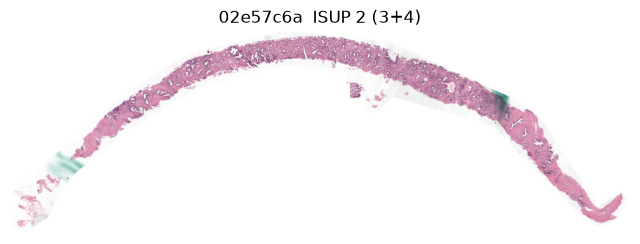

In [9]:
img = thumbnail(slide, 2)          # level 2 = the smallest zoom level
plt.figure(figsize=(8, 8))
plt.imshow(img)
plt.title(f"{row.image_id[:8]}  ISUP {row.isup_grade} ({row.gleason_score})")
plt.axis("off");

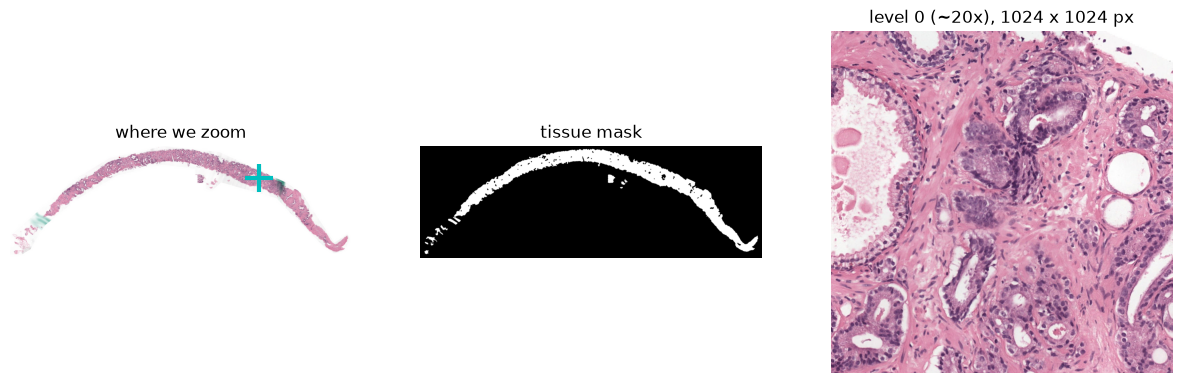

In [5]:
import numpy as np
from iris.data.tissue import tissue_mask

mask = tissue_mask(img)                 # True where there is tissue
ys, xs = np.nonzero(mask)
i = len(ys) // 2                        # a point in the middle of the tissue
down = slide.level_downsamples[2]       # level-2 pixel -> level-0 pixel
x0, y0 = int(xs[i] * down), int(ys[i] * down)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img); ax[0].plot(xs[i], ys[i], "c+", ms=20, mew=3); ax[0].set_title("where we zoom")
ax[1].imshow(mask, cmap="gray"); ax[1].set_title("tissue mask")
ax[2].imshow(slide.read_region((x0 - 512, y0 - 512), 0, (1024, 1024)).convert("RGB"))
ax[2].set_title("level 0 (~20x), 1024 x 1024 px")
for a in ax: a.axis("off")


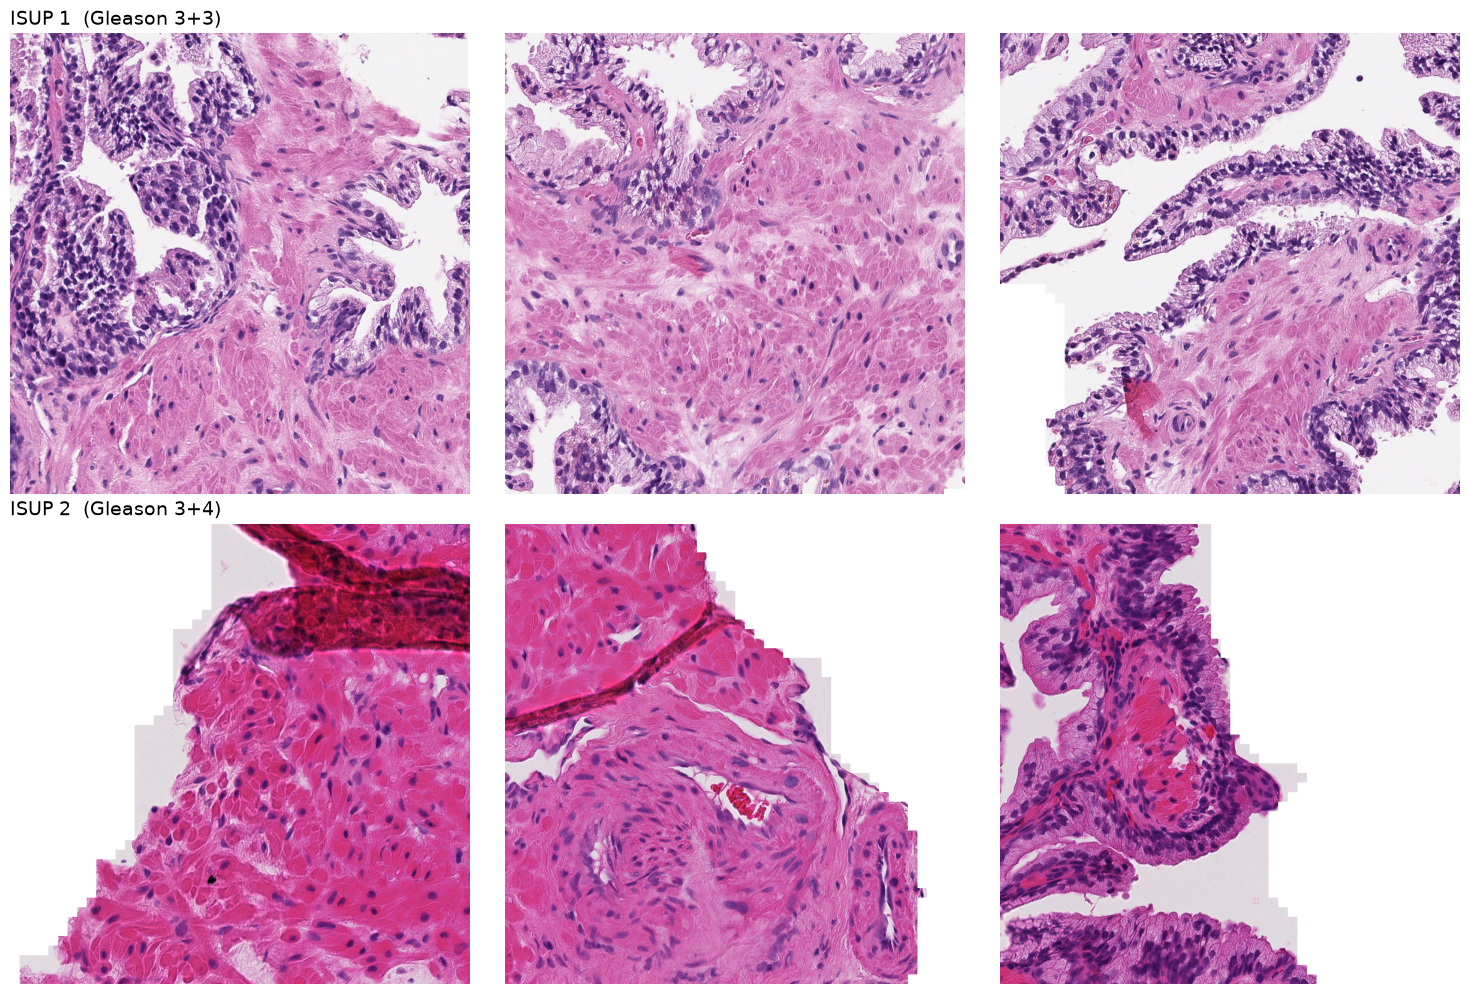

In [6]:
def zooms(row, n=3, size=768):
    """Open a slide and cut `n` full-resolution crops spread along its tissue."""
    s = open_slide(PATHS.images / f"{row.image_id}.tiff")
    small = thumbnail(s, 2)
    ys, xs = np.nonzero(tissue_mask(small))
    down = s.level_downsamples[2]
    crops = []
    for frac in np.linspace(0.2, 0.8, n):            # 20%, 50%, 80% along the tissue
        k = int(frac * len(ys))
        x0, y0 = int(xs[k] * down), int(ys[k] * down)
        crops.append(s.read_region((x0 - size // 2, y0 - size // 2), 0, (size, size)).convert("RGB"))
    return crops

# one GG1 and one GG2 slide from the SAME lab, so stain colour is comparable
lab = "karolinska"
gg1 = mine[(mine.isup_grade == 1) & (mine.data_provider == lab)].iloc[0]
gg2 = mine[(mine.isup_grade == 2) & (mine.data_provider == lab)].iloc[0]

fig, ax = plt.subplots(2, 3, figsize=(15, 10))
for r, row in enumerate([gg1, gg2]):
    for c, crop in enumerate(zooms(row)):
        ax[r, c].imshow(crop)
        ax[r, c].axis("off")
    ax[r, 0].set_title(f"ISUP {row.isup_grade}  (Gleason {row.gleason_score})", loc="left", fontsize=14)
plt.tight_layout()


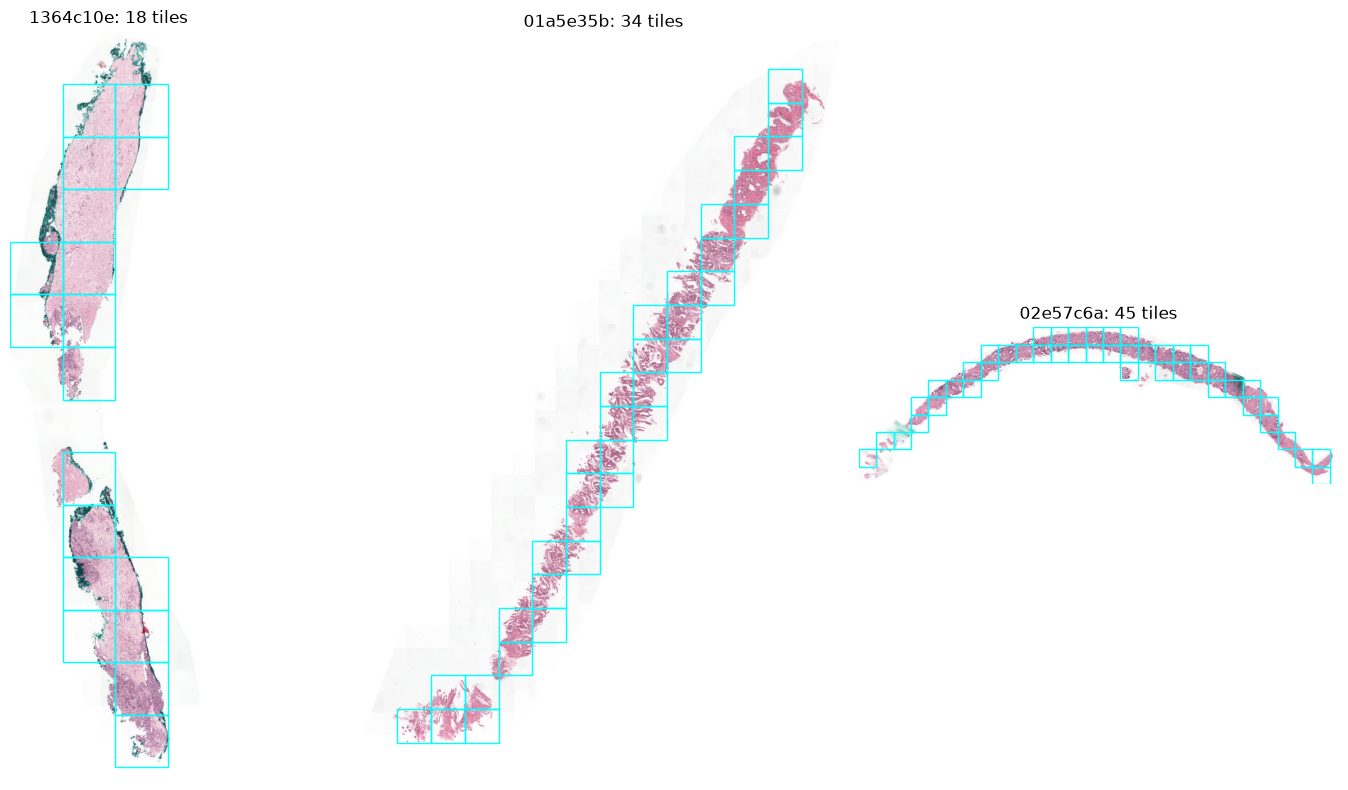

In [38]:
# Draw the tile grid on top of a slide thumbnail.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from iris.config import PATHS, TileConfig
from iris.data.tiling import open_slide, thumbnail


def draw_grid(image_id, ax):
    slide = open_slide(PATHS.images / f"{image_id}.tiff")
    img = thumbnail(slide, 2)                       # the small level-2 picture we draw on

    coords = np.load(PATHS.coords / f"{image_id}.npy")
    scale = slide.level_downsamples[2]
    side0 = TileConfig().tile_size * slide.level_downsamples[1]
    w = side0 / scale

    ax.imshow(img)
    for x, y in coords:
        ax.add_patch(Rectangle((x / scale, y / scale), w, w,
                               fill=False, edgecolor="cyan", linewidth=1))
    ax.set_title(f"{image_id[:8]}: {len(coords)} tiles")
    ax.axis("off")


# the suspicious slide + two normal ones, side by side
ids = [next(PATHS.coords.glob("1364c10e*.npy")).stem]       # the 2-tile slide
ids += [p.stem for p in sorted(PATHS.coords.glob("*.npy")) if p.stem != ids[0]][:2]

fig, axes = plt.subplots(1, 3, figsize=(15, 8))
for image_id, ax in zip(ids, axes):
    draw_grid(image_id, ax)
plt.tight_layout()


(1.0, 4.0, 16.0)


In [45]:
import torch
from iris.config import PATHS

bag = torch.load(next(PATHS.features.glob("1364c10e*.pt")), weights_only=True)
f = bag["features"]
print("shape:", f.shape)
print("first tile, first 8 numbers:", f[0, :8].float())


shape: torch.Size([18, 1024])
first tile, first 8 numbers: tensor([0.7085, 0.6772, 0.1091, 0.0879, 0.3833, 0.0734, 0.1486, 0.0221])
